## E-commerce Sales Analysis Using Python


## Project Overview

This project analyzes retail transaction data using Python to identify sales trends, customer purchasing patterns, product category performance, and payment method preferences. The analysis includes data inspection, cleaning, exploratory data analysis (EDA), and visualization to generate actionable business insights.

## Project Objectives
- Examine sales performance and trends over time.
- Analyze customer transaction activity and spending patterns.
- Identify product categories contributing to revenue.
- Compare revenue across different payment methods.
- Investigate data quality issues and document analytical limitations.
- Develop data-driven recommendations for business decision-making.
## Tools and Technologies
- Python: Data analysis and processing.
- Pandas: Data cleaning, manipulation, and aggregation.
- Matplotlib and Seaborn: Data visualization.
- Jupyter Notebook: Interactive analysis and documentation.
## Dataset Description

The dataset contains retail transactions, including transaction IDs, customer IDs, product categories, item information, prices, quantities, transaction amounts, payment methods, locations, transaction dates, and discount information.

The analysis follows a structured workflow: data loading, data quality assessment, cleaning, exploratory analysis, visualization, interpretation, and conclusions.

## 1. Data Loading and Initial Inspection


### Purpose

This section loads the raw retail sales dataset into a pandas DataFrame and examines its structure before data cleaning.

### Analytical Approach
- Import the pandas library for data manipulation.
- Load the CSV dataset using pd.read_csv().
- Display the first five records using df.head().
- Examine the dataset dimensions using df.shape.
- Inspect column names, data types, and non-null counts using df.info().
### Why This Step Matters

Initial inspection helps identify the available variables, understand the dataset's structure, and detect potential data quality issues that require further investigation.

In [1]:
import pandas as pd

# Load the raw retail sales dataset
df = pd.read_csv("data/retail_store_sales.csv")

# Display the first five rows
df.head()

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


In [2]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Examine column names, data types, and non-null counts
df.info()

Dataset shape: (12575, 11)
<class 'pandas.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    12575 non-null  str    
 1   Customer ID       12575 non-null  str    
 2   Category          12575 non-null  str    
 3   Item              11362 non-null  str    
 4   Price Per Unit    11966 non-null  float64
 5   Quantity          11971 non-null  float64
 6   Total Spent       11971 non-null  float64
 7   Payment Method    12575 non-null  str    
 8   Location          12575 non-null  str    
 9   Transaction Date  12575 non-null  str    
 10  Discount Applied  8376 non-null   object 
dtypes: float64(3), object(1), str(7)
memory usage: 1.1+ MB


## 2. Data Quality Assessment

### Purpose
This section evaluates missing data across the dataset before applying cleaning procedures.

### Analytical Approach
- Use `df.isnull().sum()` to count missing values in each column.
- Calculate missing percentages relative to the total number of records.
- Create a summary table showing missing counts and percentages.
- Identify columns requiring further investigation before deciding how to handle missing data.

### Initial Observation
The `Item` column contains 1,213 missing values, representing 9.65% of the dataset. Missing values in other columns are also assessed to determine appropriate cleaning strategies.

### Why This Step Matters
Missing data can affect the reliability of analysis and business conclusions. Examining the extent and distribution of missing values helps guide informed cleaning decisions instead of automatically deleting or replacing records.

In [3]:
# Count missing values in each column
missing_count = df.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (missing_count / len(df)) * 100

# Create a data quality summary
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage.round(2)
})

missing_summary

,Missing Values,Missing Percentage
Transaction ID,0,0.00
Customer ID,0,0.00
Category,0,0.00
Item,1213,9.65
Price Per Unit,609,4.84
Quantity,604,4.80
Total Spent,604,4.80
Payment Method,0,0.00
Location,0,0.00
Transaction Date,0,0.00


### Investigation of Missing Discount Information

**Purpose**

This analysis investigates whether missing values in the `Discount Applied` column are associated with particular payment methods or transaction locations.

**Analytical Approach**

- Identify the proportion of missing discount values.
- Use `pd.crosstab()` to compare missing discount information across payment methods.
- Apply `normalize="index"` to calculate percentages within each payment method.
- Investigate whether transaction location is associated with missing discount information.

**Key Findings**

The `Discount Applied` column contains 4,199 missing values, representing 33.39% of the dataset.

Missing discount percentages are similar across payment methods:

- Cash: 34.2%
- Credit Card: 33.1%
- Digital Wallet: 32.8%

These findings suggest that missing discount information is not strongly associated with a particular payment method.

**Why This Step Matters**

Missing discount values should not automatically be interpreted as transactions without discounts. Further investigation is necessary before deciding whether to retain, replace, or exclude these missing values.

This approach helps prevent unsupported assumptions and protects the reliability of subsequent analysis.

In [4]:
pd.crosstab(
    df["Payment Method"],
    df["Discount Applied"].isna(),
    normalize="index"
).round(3) * 100

Discount Applied,False,True
Payment Method,,
Cash,65.8,34.2
Credit Card,66.9,33.1
Digital Wallet,67.2,32.8


### Additional Finding: Transaction Location

Missing discount values were also examined across transaction locations using `pd.crosstab()`.

The results show that 33.7% of in-store transactions and 33.1% of online transactions have missing discount information.

The difference of 0.6 percentage points indicates that missing discount values occur at similar rates across both transaction locations.

Together with the payment-method analysis, these findings suggest that neither payment method nor transaction location has an obvious strong association with missing discount information. Further investigation is needed before selecting an appropriate cleaning strategy.

In [5]:
# Investigate missing discount values by transaction location
pd.crosstab(
    df["Location"],
    df["Discount Applied"].isna(),
    normalize="index"
).round(3) * 100

Discount Applied,False,True
Location,,
In-store,66.3,33.7
Online,66.9,33.1


### Investigation of Missing Discounts by Product Category

**Purpose**

This analysis examines whether missing values in the `Discount Applied` column vary across product categories.

**Analytical Approach**

The dataset was grouped by `Category` using `groupby()`. The percentage of missing discount values was calculated using `isna().mean() * 100`, and the results were sorted in descending order.

**Key Findings**

- Furniture recorded the highest missing discount percentage at 35.83%.
- Beverages followed at 35.16%.
- Computers and electric accessories recorded the lowest percentage at 30.62%.
- The difference between the highest and lowest categories was 5.21 percentage points.

**Interpretation**

Missing discount information occurs across all product categories, with moderate differences in the observed percentages.

Together with the earlier payment-method and transaction-location investigations, these findings do not reveal an obvious dominant source of missing discount information.

However, the analysis does not establish whether the missing values are completely random.

**Why This Step Matters**

Understanding missing-data patterns helps prevent inappropriate cleaning decisions. Missing discount values should not automatically be replaced with `False`, because doing so would assume that no discount was applied without sufficient evidence.

In [6]:
# Calculate missing discount percentage by product category
category_missing = (
    df.groupby("Category")["Discount Applied"]
    .apply(lambda x: x.isna().mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

category_missing

Category
Furniture                             35.83
Beverages                             35.16
Patisserie                            34.10
Electric household essentials         34.00
Food                                  33.56
Butchers                              32.59
Milk Products                         31.25
Computers and electric accessories    30.62
Name: Discount Applied, dtype: float64


### Duplicate Records and Transaction ID Validation

**Purpose**

This step checks the dataset for duplicate transaction records and repeated transaction identifiers to assess data integrity before further analysis.

**Analytical Approach**

- Use `df.duplicated().sum()` to identify completely duplicated rows.
- Use `df["Transaction ID"].duplicated().sum()` to identify repeated transaction identifiers.
- Compare the results to determine whether duplicate records require further investigation.

**Key Findings**

- Completely duplicated rows: **0**
- Repeated Transaction IDs: **0**

**Interpretation**

The results indicate that no completely duplicated rows or repeated transaction identifiers were detected in the dataset.

Each transaction has a unique identifier, supporting the reliability of transaction-level analysis.

**Why This Step Matters**

Duplicate records can inflate transaction counts, revenue totals, and customer activity metrics. Checking for duplicates helps prevent misleading business conclusions.

Since no duplicates were identified, no duplicate-removal operation is required at this stage.


In [7]:
# Check for completely duplicated rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

# Check for repeated transaction IDs
duplicate_ids = df["Transaction ID"].duplicated().sum()

print("Repeated Transaction IDs:", duplicate_ids)

Number of duplicate rows: 0
Repeated Transaction IDs: 0



### Sales Transaction Validation

**Purpose**

This step verifies the accuracy and consistency of recorded sales amounts by comparing the `Total Spent` column with the expected transaction value calculated from unit price and quantity.

**Analytical Approach**

- Select transactions containing non-missing values for `Price Per Unit`, `Quantity`, and `Total Spent`.
- Create a separate DataFrame named `sales_check` to preserve the original dataset.
- Calculate the expected transaction total using:

  **Expected Total = Price Per Unit × Quantity**

- Calculate the difference between the recorded and expected totals.
- Identify transactions where the absolute difference exceeds 0.01.
- Count inconsistent transactions and inspect the first five discrepancies, if any.

**Validation Rule**

A transaction is flagged as inconsistent when:

`abs(Total Spent - Expected Total) > 0.01`

This tolerance helps avoid flagging very small numerical differences caused by floating-point calculations.

**Why This Step Matters**

Transaction-level validation is essential for reliable financial analysis. Incorrect sales amounts can distort total revenue, average transaction value, category performance, and customer spending metrics.

Identifying discrepancies before analysis helps determine whether the recorded sales figures are suitable for calculating business performance indicators.

**Key Findings**

- Transactions checked: **11,362**
- Inconsistent transactions: **0**
- Validation pass rate: **100%**

**Interpretation**

All 11,362 transactions containing complete sales information passed the arithmetic consistency check.

For every transaction examined, the recorded `Total Spent` matched the expected value calculated from `Price Per Unit × Quantity`, within the specified tolerance of 0.01.

No discrepancies exceeding the tolerance were identified.

**Business Implications**

These findings support the arithmetic consistency of the recorded sales amounts for transactions with complete information.

The results provide confidence in using these records for revenue analysis, customer spending analysis, and product category performance comparisons.

However, transactions containing missing sales values require separate assessment before drawing conclusions about the entire dataset.



In [8]:
# Select transactions with complete sales information
sales_check = df.dropna(
    subset=["Price Per Unit", "Quantity", "Total Spent"]
).copy()

# Calculate expected transaction totals
sales_check["Expected Total"] = (
    sales_check["Price Per Unit"] * sales_check["Quantity"]
)

# Identify transactions with inconsistent totals
sales_check["Difference"] = (
    sales_check["Total Spent"] - sales_check["Expected Total"]
)

# Count transactions with meaningful differences
inconsistent_sales = sales_check[
    sales_check["Difference"].abs() > 0.01
]

print("Transactions checked:", len(sales_check))
print("Inconsistent transactions:", len(inconsistent_sales))

inconsistent_sales.head()

Transactions checked: 11362
Inconsistent transactions: 0


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied,Expected Total,Difference



### Missing Sales Data Assessment

**Purpose**

This step investigates missing values in three essential sales-related columns: `Price Per Unit`, `Quantity`, and `Total Spent`.

The objective is to determine how many transactions contain incomplete financial information and assess the potential impact on subsequent analysis.

**Analytical Approach**

- Select the three sales-related columns.
- Use `isna()` to identify missing values.
- Apply `sum(axis=1)` to count missing values within each transaction.
- Use `value_counts()` to summarize transactions according to the number of missing fields.

**Key Findings**

The dataset contains **12,575 transactions**.

- **11,362 transactions (90.35%)** have complete sales information.
- **609 transactions (4.84%)** contain one missing sales value.
- **604 transactions (4.80%)** contain two missing sales values.
- No transactions contain three missing sales values.

Overall, **1,213 transactions (9.65%)** contain at least one missing sales value.

**Interpretation**

Most transactions contain complete sales information, but a meaningful proportion have incomplete financial records.

The 11,362 complete transactions were eligible for the earlier arithmetic validation, which identified no inconsistent transaction totals.

However, the remaining 1,213 transactions could not be fully validated using the same method because one or more required sales values were missing.

**Why This Step Matters**

Missing sales information can affect revenue calculations, average transaction values, and customer spending analysis.

Understanding the extent of missingness helps determine whether missing values can be reliably reconstructed or whether some records must be excluded from specific calculations.

Rather than automatically deleting incomplete transactions, further investigation is necessary to preserve as much valid information as possible.


In [9]:
# Examine missing values in sales-related columns
sales_columns = [
    "Price Per Unit",
    "Quantity",
    "Total Spent"
]

# Count missing values in each row
missing_sales_count = df[sales_columns].isna().sum(axis=1)

# Summarize how many transactions have 0, 1, 2, or 3 missing values
print("Missing numerical values per transaction:")
print(missing_sales_count.value_counts().sort_index())

Missing numerical values per transaction:
0    11362
1      609
2      604
Name: count, dtype: int64



### Investigation of Missing Sales Value Patterns

**Purpose**

This analysis identifies which sales-related fields are missing together to determine whether incomplete transaction records can be recovered.

**Analytical Approach**

- Select `Price Per Unit`, `Quantity`, and `Total Spent`.
- Use `isna()` to identify missing values.
- Apply `value_counts()` to count each combination of missing and available values.

**Key Findings**

Three missing-value patterns were identified:

1. **11,362 transactions** have complete sales information.
2. **609 transactions** have missing unit prices but available quantities and transaction totals.
3. **604 transactions** have missing quantities and transaction totals but available unit prices.

**Interpretation**

The 609 transactions with missing unit prices may be recoverable using:

`Price Per Unit = Total Spent / Quantity`

However, the 604 transactions missing both quantity and total spent cannot be reconstructed using the available unit price alone.

**Why This Step Matters**

Identifying missing-value patterns supports targeted data cleaning rather than indiscriminately removing incomplete records.

Recovering valid unit prices may preserve additional transactions for analysis, while records missing essential sales information may need to be excluded from revenue calculations.

Any recovery or exclusion decisions should be documented to maintain transparency and reproducibility.


In [10]:
# Identify missing-value patterns in sales columns
missing_patterns = (
    df[sales_columns]
    .isna()
    .value_counts()
)

print("Missing-value patterns:")
print(missing_patterns)

Missing-value patterns:
Price Per Unit  Quantity  Total Spent
False           False     False          11362
True            False     False            609
False           True      True             604
Name: count, dtype: int64



### Validation of Transactions with Missing Unit Prices

**Purpose**

This step evaluates whether transactions with missing unit prices contain sufficient information to reconstruct those prices reliably.

**Analytical Approach**

- Identify transactions where `Price Per Unit` is missing.
- Count missing quantity values.
- Check for zero and negative quantities.
- Preview the corresponding quantity and transaction total values.

**Key Findings**

- Transactions with missing unit prices: **609**
- Transactions with missing quantities: **0**
- Transactions with zero quantities: **0**
- Transactions with negative quantities: **0**

**Interpretation**

All 609 transactions have valid positive quantities. The earlier missing-value analysis also confirmed that their `Total Spent` values are available.

Therefore, the missing unit prices can potentially be reconstructed using:

`Price Per Unit = Total Spent / Quantity`

For example, a transaction with a total of 200 and quantity of 10 produces a unit price of 20.

**Why This Step Matters**

Reconstructing missing unit prices from existing transaction information is preferable to replacing them with arbitrary averages.

This approach preserves the transaction-specific relationship between quantity, unit price, and total spent.

The reconstructed values should be checked before being incorporated into the cleaned dataset.


In [11]:
# Select transactions with missing unit prices
missing_prices = df[
    df["Price Per Unit"].isna()
].copy()

# Examine quantity values before calculating prices
print("Transactions with missing prices:", len(missing_prices))

print(
    "Missing quantities:",
    missing_prices["Quantity"].isna().sum()
)

print(
    "Zero quantities:",
    (missing_prices["Quantity"] == 0).sum()
)

print(
    "Negative quantities:",
    (missing_prices["Quantity"] < 0).sum()
)

# Preview transactions
missing_prices[
    ["Price Per Unit", "Quantity", "Total Spent"]
].head()

Transactions with missing prices: 609
Missing quantities: 0
Zero quantities: 0
Negative quantities: 0


,Price Per Unit,Quantity,Total Spent
5,NaN,10.0,200.0
11,NaN,8.0,52.0
17,NaN,10.0,275.0
21,NaN,3.0,105.0
32,NaN,8.0,196.0



### Reconstruction of Missing Unit Prices

**Purpose**

This step calculates candidate unit prices for the 609 transactions identified as having missing `Price Per Unit` values.

**Analytical Approach**

- Use the available `Total Spent` and `Quantity` values.
- Calculate the missing unit prices using:

  `Calculated Price = Total Spent / Quantity`

- Apply `describe()` to examine the distribution of reconstructed prices.
- Preview the calculated values alongside their corresponding quantities and transaction totals.

**Key Findings**

- Candidate unit prices calculated: **609**
- Mean calculated price: **23.44**
- Median calculated price: **23.00**
- Minimum calculated price: **5.00**
- Maximum calculated price: **41.00**
- Standard deviation: **10.86**

**Interpretation**

The reconstructed unit prices range from 5.00 to 41.00, with an average of approximately 23.44.

The relatively close mean and median suggest that the calculated prices are not strongly skewed overall.

However, these descriptive statistics alone do not establish that every reconstructed value is valid.

**Why This Step Matters**

Calculating missing unit prices from available transaction information can preserve records that might otherwise be excluded from analysis.

Unlike replacing missing values with a general average, this method uses each transaction's actual quantity and total spending.

Before updating the cleaned dataset, the reconstructed prices should be compared with existing valid unit prices to confirm that they are consistent with the dataset's pricing structure.


In [12]:
# Calculate candidate unit prices
missing_prices["Calculated Price"] = (
    missing_prices["Total Spent"] /
    missing_prices["Quantity"]
)

# Examine the calculated prices
print(missing_prices["Calculated Price"].describe())

# Preview the first 10 transactions
missing_prices[
    ["Quantity", "Total Spent", "Calculated Price"]
].head(10)

count    609.000000
mean      23.435961
std       10.859260
min        5.000000
25%       14.000000
50%       23.000000
75%       33.500000
max       41.000000
Name: Calculated Price, dtype: float64


,Quantity,Total Spent,Calculated Price
5,10.0,200.0,20.0
11,8.0,52.0,6.5
17,10.0,275.0,27.5
21,3.0,105.0,35.0
32,8.0,196.0,24.5
127,10.0,275.0,27.5
159,9.0,126.0,14.0
216,8.0,40.0,5.0
247,7.0,150.5,21.5
271,9.0,99.0,11.0



### Validation of Reconstructed Unit Prices

**Purpose**

This step evaluates whether the reconstructed unit prices are consistent with the existing valid prices in the dataset.

**Analytical Approach**

- Generate descriptive statistics for existing unit prices.
- Compare them with the reconstructed unit prices.
- Examine differences in the mean, standard deviation, minimum, median, and maximum.
- Check whether any reconstructed prices are zero or negative.

**Key Findings**

The existing and reconstructed prices have similar distributions.

| Statistic | Existing Prices | Reconstructed Prices |
|---|---:|---:|
| Mean | 23.37 | 23.44 |
| Standard Deviation | 10.74 | 10.86 |
| Minimum | 5.00 | 5.00 |
| Median | 23.00 | 23.00 |
| Maximum | 41.00 | 41.00 |

**Interpretation**

The reconstructed prices closely resemble the existing unit prices.

Both groups share the same minimum, median, and maximum values. Their means and standard deviations are also similar.

These findings provide evidence that the reconstructed values are plausible and consistent with the overall pricing distribution.

However, distributional similarity alone does not prove that every reconstructed price is correct.

**Why This Step Matters**

Validating reconstructed values before incorporating them into the cleaned dataset reduces the risk of introducing unrealistic prices.

This helps preserve data quality and supports more reliable sales and customer analysis.


In [13]:
# Examine the range of existing unit prices
print("Existing unit prices:")
print(df["Price Per Unit"].describe())

# Examine the range of calculated unit prices
print("\nCalculated unit prices:")
print(missing_prices["Calculated Price"].describe())

# Check for invalid calculated prices
print(
    "\nZero or negative calculated prices:",
    (missing_prices["Calculated Price"] <= 0).sum()
)

Existing unit prices:
count    11966.000000
mean        23.365912
std         10.743519
min          5.000000
25%         14.000000
50%         23.000000
75%         33.500000
max         41.000000
Name: Price Per Unit, dtype: float64

Calculated unit prices:
count    609.000000
mean      23.435961
std       10.859260
min        5.000000
25%       14.000000
50%       23.000000
75%       33.500000
max       41.000000
Name: Calculated Price, dtype: float64

Zero or negative calculated prices: 0



### Recovery of Missing Unit Prices

**Purpose**

This step recovers missing unit prices using available transaction information while preserving the original dataset.

**Analytical Approach**

- Create a separate working copy of the dataset using `df.copy()`.
- Identify records where `Price Per Unit` is missing.
- Calculate the missing prices using `Total Spent / Quantity`.
- Update only the missing unit price values in the cleaned dataset.
- Verify the number of missing prices before and after recovery.
- Confirm that the total number of transactions remains unchanged.

**Key Findings**

- Missing unit prices before recovery: **609**
- Missing unit prices after recovery: **0**
- Total transactions retained: **12,575**
- Zero or negative reconstructed prices: **0**

**Interpretation**

All 609 missing unit prices were successfully reconstructed using the corresponding transaction totals and quantities.

The recovery process preserved all 12,575 transactions and did not modify the original DataFrame.

The reconstructed prices were previously checked against the distribution of existing unit prices and found to be consistent with the observed pricing range.

**Why This Step Matters**

Recovering missing values using mathematically related fields helps preserve valuable transaction records without introducing arbitrary estimates.

Maintaining the original dataset separately also improves reproducibility and makes it easier to review the cleaning decisions.

This process strengthens the reliability and transparency of the subsequent sales analysis.


In [14]:
# Create a copy to preserve the original dataset
df_clean = df.copy()

# Identify transactions with missing unit prices
missing_price_mask = df_clean["Price Per Unit"].isna()

# Recover missing unit prices using total spent and quantity
df_clean.loc[missing_price_mask, "Price Per Unit"] = (
    df_clean.loc[missing_price_mask, "Total Spent"] /
    df_clean.loc[missing_price_mask, "Quantity"]
)

# Verify the recovery
print("Missing unit prices before:", df["Price Per Unit"].isna().sum())

print("Missing unit prices after:", df_clean["Price Per Unit"].isna().sum())

print("Total transactions:", len(df_clean))

Missing unit prices before: 609
Missing unit prices after: 0
Total transactions: 12575



### Investigation of Missing Quantity and Total Spent

**Purpose**

This step investigates transactions where both `Quantity` and `Total Spent` are missing to determine whether the missing values can be recovered reliably.

**Analytical Approach**

- Identify transactions where both `Quantity` and `Total Spent` contain missing values.
- Count the affected transactions.
- Examine the available transaction identifiers, customer information, product categories, item descriptions, and unit prices.
- Assess whether the missing values can be reconstructed without making unsupported assumptions.

**Key Findings**

- **604 transactions** have missing values in both `Quantity` and `Total Spent`.
- These transactions cannot be reconstructed using unit price alone because both the quantity purchased and total transaction amount are unknown.

**Interpretation**

Unlike missing unit prices, which were recovered using known transaction totals and quantities, these records lack sufficient numerical information for direct reconstruction.

Estimating the missing values without additional evidence could introduce inaccurate sales figures.

**Cleaning Decision**

Retain the affected records in the working dataset for now. Exclude them from calculations requiring complete sales information, while preserving them for analyses that can use their available fields.

**Why This Step Matters**

Distinguishing recoverable missing values from unrecoverable ones helps prevent misleading financial calculations and unnecessary loss of potentially useful customer and transaction information.


In [15]:
# Identify transactions missing quantity and total spent
missing_sales = df_clean[
    df_clean["Quantity"].isna() &
    df_clean["Total Spent"].isna()
].copy()

# Count affected transactions
print("Transactions missing both values:", len(missing_sales))

# Examine their available information
missing_sales[
    [
        "Transaction ID",
        "Customer ID",
        "Category",
        "Item",
        "Price Per Unit",
        "Quantity",
        "Total Spent"
    ]
].head(10)

Transactions missing both values: 604


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent
7,TXN_1372952,CUST_21,Furniture,NaN,33.5,NaN,NaN
15,TXN_1809665,CUST_14,Beverages,NaN,24.5,NaN,NaN
19,TXN_4206593,CUST_01,Furniture,NaN,35.0,NaN,NaN
25,TXN_3481599,CUST_05,Furniture,NaN,39.5,NaN,NaN
34,TXN_1621497,CUST_06,Patisserie,NaN,23.0,NaN,NaN
83,TXN_4532214,CUST_25,Patisserie,NaN,15.5,NaN,NaN
112,TXN_5419965,CUST_23,Computers and electric accessories,NaN,20.0,NaN,NaN
114,TXN_8210621,CUST_03,Beverages,NaN,39.5,NaN,NaN
118,TXN_8586300,CUST_11,Computers and electric accessories,NaN,27.5,NaN,NaN
138,TXN_1154680,CUST_25,Furniture,NaN,35.0,NaN,NaN



### Investigation of Missing Sales and Item Information

**Purpose**

This step examines whether transactions missing both `Quantity` and `Total Spent` also have missing product information in the `Item` column.

**Analytical Approach**

- Identify the 604 transactions with missing quantity and total spending values.
- Count missing and available `Item` values within these transactions.
- Investigate whether the missing fields occur together.

**Key Findings**

- Total affected transactions: **604**
- Transactions with missing `Item` information: **604**
- Transactions with available `Item` information: **0**
- All affected transactions (100%) are missing all three fields.

**Interpretation**

The results reveal a consistent pattern: every transaction missing both `Quantity` and `Total Spent` also lacks `Item` information.

This suggests that the missing fields may be related to a common data-recording or data-generation process. However, the underlying cause cannot be established from this analysis alone.

**Cleaning Decision**

Preserve these records in the working dataset while investigating their distribution across transaction years.

For revenue calculations, records without quantity and total spending information should be excluded rather than assigned unsupported values.

**Why This Step Matters**

Identifying relationships between missing fields helps analysts make more defensible cleaning decisions and avoid introducing inaccurate information into financial reports.


In [16]:
# Check whether missing sales values are associated
# with missing item information

print("Total affected transactions:", len(missing_sales))

print(
    "Missing Item values:",
    missing_sales["Item"].isna().sum()
)

print(
    "Item values available:",
    missing_sales["Item"].notna().sum()
)

Total affected transactions: 604
Missing Item values: 604
Item values available: 0



### Investigation of Incomplete Sales Transactions by Year

**Purpose**

This analysis examines whether transactions missing both `Quantity` and `Total Spent` are concentrated in particular transaction years.

**Analytical Approach**

- Convert `Transaction Date` into a datetime format.
- Extract the transaction year.
- Identify records where both `Quantity` and `Total Spent` are missing.
- Group transactions by year and calculate the percentage of incomplete records.

**Key Findings**

The percentage of incomplete transactions by year was:

- **2022:** 5.06%
- **2023:** 4.49%
- **2024:** 4.83%
- **2025:** 5.16%

The highest percentage occurred in 2025, while the lowest occurred in 2023.

The difference between the highest and lowest percentages was **0.67 percentage points**.

**Interpretation**

Incomplete sales transactions occur at relatively similar rates across the four years.

The findings do not indicate a substantial concentration of missing sales information in any particular year.

However, this analysis alone cannot establish whether the missing values are random or identify their underlying cause.

Additionally, the 2025 data covers only part of the year, so its results should not be interpreted as representing the entire year.

**Cleaning Decision**

Continue investigating incomplete transactions across product categories before finalizing the missing-data treatment strategy.

**Why This Step Matters**

Examining missing-data patterns over time helps identify potential periods of data-quality problems and supports more reliable decisions about preparing transaction records for financial analysis.


In [17]:
# Investigate missing sales records by transaction year

# Extract the transaction year
df_clean["Transaction Year"] = pd.to_datetime(
    df_clean["Transaction Date"]
).dt.year

# Identify records missing both Quantity and Total Spent
missing_sales_mask = (
    df_clean["Quantity"].isna() &
    df_clean["Total Spent"].isna()
)

# Calculate the percentage of incomplete transactions per year
year_missing = (
    df_clean.groupby("Transaction Year")
    .apply(
        lambda group: (
            group["Quantity"].isna() &
            group["Total Spent"].isna()
        ).mean() * 100,
        include_groups=False
    )
    .round(2)
)

print("Percentage of incomplete transactions by year:")
print(year_missing)

Percentage of incomplete transactions by year:
Transaction Year
2022    5.06
2023    4.49
2024    4.83
2025    5.16
dtype: float64



### Investigation of Incomplete Sales Transactions by Product Category

**Purpose**

This analysis investigates whether transactions missing both `Quantity` and `Total Spent` are concentrated in specific product categories.

**Analytical Approach**

- Identify transactions where both sales-related fields are missing.
- Group transactions by product category.
- Calculate the number of incomplete transactions in each category.
- Calculate the percentage of incomplete transactions relative to the total transactions in each category.
- Sort categories by missing percentage to identify potential data-quality concerns.

**Key Findings**

Among the categories examined in the visible results:

- Patisserie recorded 87 incomplete transactions (5.69%).
- Computers and electric accessories recorded 81 (5.20%).
- Food recorded 81 (5.10%).
- Electric household essentials recorded 75 (4.71%).
- Butchers recorded 72 (4.59%).
- Beverages recorded 71 (4.53%).

**Interpretation**

The visible results show that incomplete sales transactions occur across multiple product categories.

Patisserie has the highest observed missing rate among the categories displayed.

The findings do not yet establish whether any product category is disproportionately affected, because the remaining category results must also be reviewed.

**Why This Step Matters**

Examining missing sales information by category helps identify potential data-quality patterns and supports informed decisions about which records can be used in revenue and product-performance analysis.


In [18]:
# Investigate incomplete transactions by product category

category_missing = (
    df_clean.assign(
        Incomplete_Transaction=(
            df_clean["Quantity"].isna() &
            df_clean["Total Spent"].isna()
        )
    )
    .groupby("Category")["Incomplete_Transaction"]
    .agg(["sum", "count", "mean"])
)

# Rename columns for readability
category_missing.columns = [
    "Incomplete Transactions",
    "Total Transactions",
    "Missing Rate"
]

# Convert missing rate to percentage
category_missing["Missing Rate"] = (
    category_missing["Missing Rate"] * 100
).round(2)

# Sort categories by missing percentage
category_missing = category_missing.sort_values(
    "Missing Rate",
    ascending=False
)

category_missing

,Incomplete Transactions,Total Transactions,Missing Rate
Category,,,
Patisserie,87,1528,5.69
Computers and electric accessories,81,1558,5.20
Food,81,1588,5.10
Electric household essentials,75,1591,4.71
Butchers,72,1568,4.59
Beverages,71,1567,4.53
Milk Products,71,1584,4.48
Furniture,66,1591,4.15



### Data Quality Assessment: Incomplete Transactions by Payment Method

**Objective**

Investigate whether incomplete sales transactions are associated with specific payment methods.

**Analytical Approach**

- Identify transactions with missing values in both `Quantity` and `Total Spent`.
- Group transactions by `Payment Method`.
- Calculate the number of incomplete transactions, total transactions, and missing percentage for each payment method.
- Compare missing rates to identify potential patterns.

**Key Findings**

- Cash: 207 incomplete transactions out of 4,310 (4.80%).
- Credit Card: 194 incomplete transactions out of 4,121 (4.71%).
- Digital Wallet: 203 incomplete transactions out of 4,144 (4.90%).
- Overall: 604 incomplete transactions out of 12,575 (4.80%).

**Interpretation**

Incomplete transaction rates are similar across all three payment methods. Digital Wallet has the highest missing rate, while Credit Card has the lowest. However, the difference is only 0.19 percentage points.

These results provide no strong descriptive evidence that missing sales information is concentrated in a particular payment method.

**Why This Step Matters**

Understanding missing-data patterns helps determine whether data-quality problems are concentrated within particular transaction groups.

Because the 604 incomplete transactions lack both quantity and total spending information, they cannot be reliably used to calculate revenue without additional information.

These records should be excluded from revenue calculations while preserving the original data for further investigation.


In [19]:
# Check incomplete sales transactions by payment method

payment_missing = (
    df_clean.assign(
        Incomplete_Transaction=(
            df_clean["Quantity"].isna() &
            df_clean["Total Spent"].isna()
        )
    )
    .groupby("Payment Method")["Incomplete_Transaction"]
    .agg(["sum", "count", "mean"])
)

payment_missing.columns = [
    "Incomplete Transactions",
    "Total Transactions",
    "Missing Rate"
]

payment_missing["Missing Rate"] = (
    payment_missing["Missing Rate"] * 100
).round(2)

payment_missing

,Incomplete Transactions,Total Transactions,Missing Rate
Payment Method,,,
Cash,207,4310,4.80
Credit Card,194,4121,4.71
Digital Wallet,203,4144,4.90



### Step 29: Preparing a Reliable Dataset for Revenue Analysis

**Objective**

Create a dedicated dataset containing transactions with complete information required for revenue analysis while preserving the cleaned dataset.

**Analytical Approach**

- Create a separate copy of `df_clean` named `df_revenue`.
- Remove transactions with missing values in `Item`, `Price Per Unit`, `Quantity`, or `Total Spent`.
- Compare the original and revenue-ready transaction counts.
- Verify that the required columns contain no remaining missing values.

**Key Findings**

- Original transactions: **12,575**
- Revenue-ready transactions: **11,362**
- Transactions excluded: **1,213**
- Transactions retained: **90.35%**
- Remaining missing values in the four required columns: **0**

**Interpretation**

The revenue-ready dataset contains 11,362 transactions with complete item and sales information.

A total of 1,213 transactions were excluded because at least one required field was missing. This includes the 604 transactions previously identified as missing both quantity and total spending information.

The resulting dataset is suitable for revenue analysis based on complete recorded transactions.

**Why This Step Matters**

Incomplete transaction records can affect revenue calculations and product-level comparisons.

By separating the revenue-ready dataset from the cleaned dataset, we preserve the original records for further investigation while maintaining consistent inputs for revenue analysis.

**Limitation**

Revenue results calculated from `df_revenue` represent the 11,362 retained transactions rather than all 12,575 original records. Excluding incomplete transactions may affect revenue estimates if the excluded records differ systematically from those retained.


In [20]:
# STEP 29: Prepare a reliable dataset for revenue analysis

# Preserve df_clean and create a separate revenue dataset
df_revenue = df_clean.copy()

# Keep transactions with valid sales information
df_revenue = df_revenue.dropna(
    subset=[
        "Item",
        "Price Per Unit",
        "Quantity",
        "Total Spent"
    ]
).copy()

# Verify the cleaning results
print("Original transactions:", len(df_clean))

print("Revenue-ready transactions:", len(df_revenue))

print(
    "Transactions excluded:",
    len(df_clean) - len(df_revenue)
)

# Check remaining missing values
print("\nRemaining missing sales values:")

print(
    df_revenue[
        ["Item", "Price Per Unit", "Quantity", "Total Spent"]
    ].isna().sum()
)

Original transactions: 12575
Revenue-ready transactions: 11362
Transactions excluded: 1213

Remaining missing sales values:
Item              0
Price Per Unit    0
Quantity          0
Total Spent       0
dtype: int64



### Step 30: Verification of Recovered Unit Prices

**Objective**

Verify that missing unit prices were successfully recovered during data cleaning and that the recovered values remain available in the revenue-ready dataset.

**Analytical Approach**

- Count missing unit prices in the original dataset (`df`).
- Count missing unit prices in the cleaned dataset (`df_clean`).
- Verify that the revenue-ready dataset (`df_revenue`) contains no missing unit prices.
- Compare the results to confirm that the cleaning process was successful.

**Key Findings**

- Original dataset: **609 missing unit prices**
- Cleaned dataset: **0 missing unit prices**
- Revenue-ready dataset: **0 missing unit prices**

**Interpretation**

The original dataset contained 609 transactions with missing unit prices.

These values were recovered using the relationship:

`Price Per Unit = Total Spent / Quantity`

The cleaned dataset now contains no missing unit prices, and the revenue-ready dataset also contains no missing unit prices.

**Why This Step Matters**

Recovering unit prices from existing transaction information helps preserve useful data and reduces unnecessary data loss.

Verifying the results ensures that subsequent revenue analysis uses complete unit-price information.

**Limitation**

This verification confirms that no unit prices remain missing. It does not independently verify the accuracy of every recovered value.


In [21]:
# Check whether recovered unit prices remain in df_clean

print(
    "Missing unit prices in df:",
    df["Price Per Unit"].isna().sum()
)

print(
    "Missing unit prices in df_clean:",
    df_clean["Price Per Unit"].isna().sum()
)

print(
    "Missing unit prices in df_revenue:",
    df_revenue["Price Per Unit"].isna().sum()
)

Missing unit prices in df: 609
Missing unit prices in df_clean: 0
Missing unit prices in df_revenue: 0



### Step 31: Investigating Excluded Transactions

**Objective**

Identify the missing-data conditions responsible for excluding transactions from the revenue-ready dataset.

**Analytical Approach**

- Compare transaction counts across the original, cleaned, and revenue-ready datasets.
- Examine missing values in the `Item`, `Price Per Unit`, `Quantity`, and `Total Spent` columns.
- Determine which missing fields contribute to transaction exclusions.
- Assess the implications for subsequent revenue analysis.

**Key Findings**

- Original transactions: **12,575**
- Cleaned transactions: **12,575**
- Revenue-ready transactions: **11,362**
- Excluded transactions: **1,213**

Missing values in the cleaned dataset:

- `Item`: **1,213**
- `Price Per Unit`: **0**
- `Quantity`: **604**
- `Total Spent`: **604**

**Interpretation**

The primary reason for transaction exclusion is missing item information.

Earlier investigations established that the 604 transactions missing both quantity and total spending also have missing item values.

Therefore, the 1,213 excluded transactions include these 604 incomplete sales records and 609 additional transactions with missing item information.

All 609 originally missing unit prices were successfully recovered during cleaning.

**Why This Step Matters**

Understanding why transactions are excluded helps prevent unnecessary data loss and supports transparent analytical decisions.

Missing item information prevents reliable item-level analysis, but it does not necessarily make a transaction unusable for overall revenue calculations.

**Analytical Consideration**

The current revenue-ready dataset requires complete item and sales information. A separate dataset requiring only valid spending amounts may retain additional transactions for overall revenue analysis.

This distinction should be considered before finalizing revenue calculations.


In [22]:
# Step 31: Investigate excluded transactions

print("Original transactions:", len(df))

print("Cleaned transactions:", len(df_clean))

print("Revenue-ready transactions:", len(df_revenue))

print("\nMissing values in df_clean:")

print(
    df_clean[
        ["Item", "Price Per Unit", "Quantity", "Total Spent"]
    ].isna().sum()
)

Original transactions: 12575
Cleaned transactions: 12575
Revenue-ready transactions: 11362

Missing values in df_clean:
Item              1213
Price Per Unit       0
Quantity           604
Total Spent        604
dtype: int64



### Step 32: Identifying Recoverable Transactions with Missing Item Information

**Objective**

Determine whether transactions excluded because of missing item information can still contribute to overall revenue analysis.

**Analytical Approach**

- Identify transactions with missing `Item` values.
- Examine whether `Price Per Unit`, `Quantity`, and `Total Spent` are available.
- Count transactions with complete financial information.
- Distinguish transactions suitable for overall revenue analysis from those requiring further investigation.

**Key Findings**

- Transactions missing item information: **1,213**
- Transactions with missing item information but complete sales data: **609**
- Transactions missing item information and incomplete sales data: **604**

**Interpretation**

Of the 1,213 transactions missing item information, 609 contain complete financial information.

Although these transactions cannot be reliably assigned to specific products, their recorded spending values can still contribute to overall revenue calculations.

The remaining 604 transactions lack essential sales information and cannot be reliably included in revenue calculations without additional data.

**Why This Step Matters**

Excluding every transaction with missing item information would unnecessarily remove valid revenue data.

Separating overall revenue analysis from item-level analysis allows us to preserve more useful observations without inventing missing product information.

**Recommended Analytical Decision**

- Retain the 609 transactions for overall revenue analysis.
- Exclude them from item-level revenue comparisons.
- Keep the 604 transactions with incomplete sales information outside revenue calculations.
- Preserve all original records for transparency and future investigation.

**Limitation**

The 609 transactions cannot be attributed to specific products without additional information.


In [23]:
# Step 32: Investigate transactions with missing Item values

missing_item = df_clean[df_clean["Item"].isna()]

# Check how many have complete sales information
recoverable = missing_item[
    missing_item[
        ["Price Per Unit", "Quantity", "Total Spent"]
    ].notna().all(axis=1)
]

print("Transactions missing Item:", len(missing_item))

print("Missing Item but complete sales data:", len(recoverable))

print("\nSample recoverable transactions:")

display(
    recoverable[
        ["Category", "Item", "Price Per Unit",
         "Quantity", "Total Spent"]
    ].head(10)
)

Transactions missing Item: 1213
Missing Item but complete sales data: 609

Sample recoverable transactions:


,Category,Item,Price Per Unit,Quantity,Total Spent
5,Patisserie,NaN,20.0,10.0,200.0
11,Milk Products,NaN,6.5,8.0,52.0
17,Milk Products,NaN,27.5,10.0,275.0
21,Milk Products,NaN,35.0,3.0,105.0
32,Food,NaN,24.5,8.0,196.0
127,Butchers,NaN,27.5,10.0,275.0
159,Butchers,NaN,14.0,9.0,126.0
216,Patisserie,NaN,5.0,8.0,40.0
247,Electric household essentials,NaN,21.5,7.0,150.5
271,Milk Products,NaN,11.0,9.0,99.0



### Step 33: Creating the Corrected Revenue-Ready Dataset

**Objective:** Preserve all transactions containing complete financial information for accurate overall revenue analysis.

**Method:**
- Start with the cleaned dataset.
- Exclude transactions missing essential financial values.
- Retain transactions with missing item names when their financial information is complete.
- Verify the number of retained and excluded transactions.

**Results:**
- Original transactions: 12,575
- Revenue-ready transactions: 11,971
- Excluded transactions: 604
- Additional transactions recovered: 609

**Interpretation:**

The corrected dataset retains 609 additional transactions that were previously excluded because of missing item information.

These transactions can contribute to overall revenue analysis but should not be used for item-level comparisons.

**Conclusion:**

The revised cleaning approach preserves more valid financial data while maintaining transparency about missing product information.


In [24]:
# Step 33: Create the corrected revenue-ready dataset

df_revenue = df_clean.dropna(
    subset=["Price Per Unit", "Quantity", "Total Spent"]
).copy()

# Check the results
print("Original transactions:", len(df))

print("Revenue-ready transactions:", len(df_revenue))

print("Excluded transactions:", len(df) - len(df_revenue))

# Check missing values in important sales columns
print("\nRemaining missing sales values:")

print(
    df_revenue[
        ["Price Per Unit", "Quantity", "Total Spent"]
    ].isna().sum()
)

Original transactions: 12575
Revenue-ready transactions: 11971
Excluded transactions: 604

Remaining missing sales values:
Price Per Unit    0
Quantity          0
Total Spent       0
dtype: int64



### Step 34: Overall Sales Performance

**Objective:** Evaluate the overall financial performance of the e-commerce business.

**Key Performance Indicators (KPIs):**
- Total Revenue: 1,552,071.00
- Average Transaction Value: 129.65
- Total Revenue-Ready Transactions: 11,971

**Interpretation:**

The business generated total recorded revenue of 1,552,071.00 across 11,971 transactions with complete financial information.

The average transaction value was approximately 129.65, representing the average amount spent per retained transaction.

These metrics establish a baseline for evaluating revenue performance across product categories and over time.

**Limitation:** The results exclude 604 transactions with incomplete financial information.


In [25]:
# Step 34: Calculate overall sales performance

# Calculate total revenue
total_revenue = df_revenue["Total Spent"].sum()

# Calculate average transaction value
average_transaction = df_revenue["Total Spent"].mean()

# Count revenue-ready transactions
total_transactions = len(df_revenue)

# Display results
print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Average Transaction Value: {average_transaction:,.2f}")
print(f"Total Transactions: {total_transactions:,}")

Total Revenue: 1,552,071.00
Average Transaction Value: 129.65
Total Transactions: 11,971



### Step 35: Revenue Performance by Product Category

**Objective:** Identify which product categories contribute the most to total sales revenue.

**Key Findings:**

- Butchers generated the highest revenue (208,118.00).
- Electric household essentials ranked second (203,813.50).
- Milk Products generated the lowest revenue (180,112.00).
- Revenue was distributed across eight product categories.

**Business Interpretation:**

Butchers and Electric household essentials were the leading revenue-generating categories.

However, revenue alone does not measure profitability. Additional information about product costs and profit margins would be required to determine which categories contribute the most profit.

**Limitation:** The analysis includes transactions with complete financial information.


In [26]:
# Step 35: Calculate total revenue by product category

category_revenue = (
    df_revenue.groupby("Category")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

# Display category revenue
print("Total Revenue by Product Category:")
print(category_revenue.round(2))

Total Revenue by Product Category:
Category
Butchers                              208118.0
Electric household essentials         203813.5
Beverages                             197047.5
Furniture                             195310.0
Food                                  194812.0
Computers and electric accessories    190692.5
Patisserie                            182165.5
Milk Products                         180112.0
Name: Total Spent, dtype: float64


In [27]:

# Step 36: Calculate percentage contribution by category

# Calculate each category's percentage of total revenue
category_percentage = (
    category_revenue / total_revenue
) * 100

# Round results to two decimal places
category_percentage = category_percentage.round(2)

# Display results
print("Percentage Revenue Contribution by Category:")
print(category_percentage)

# Verify that all percentages add up to approximately 100%
print(
    "\nTotal Percentage:",
    category_percentage.sum().round(2)
)


Percentage Revenue Contribution by Category:
Category
Butchers                              13.41
Electric household essentials         13.13
Beverages                             12.70
Furniture                             12.58
Food                                  12.55
Computers and electric accessories    12.29
Patisserie                            11.74
Milk Products                         11.60
Name: Total Spent, dtype: float64

Total Percentage: 100.0


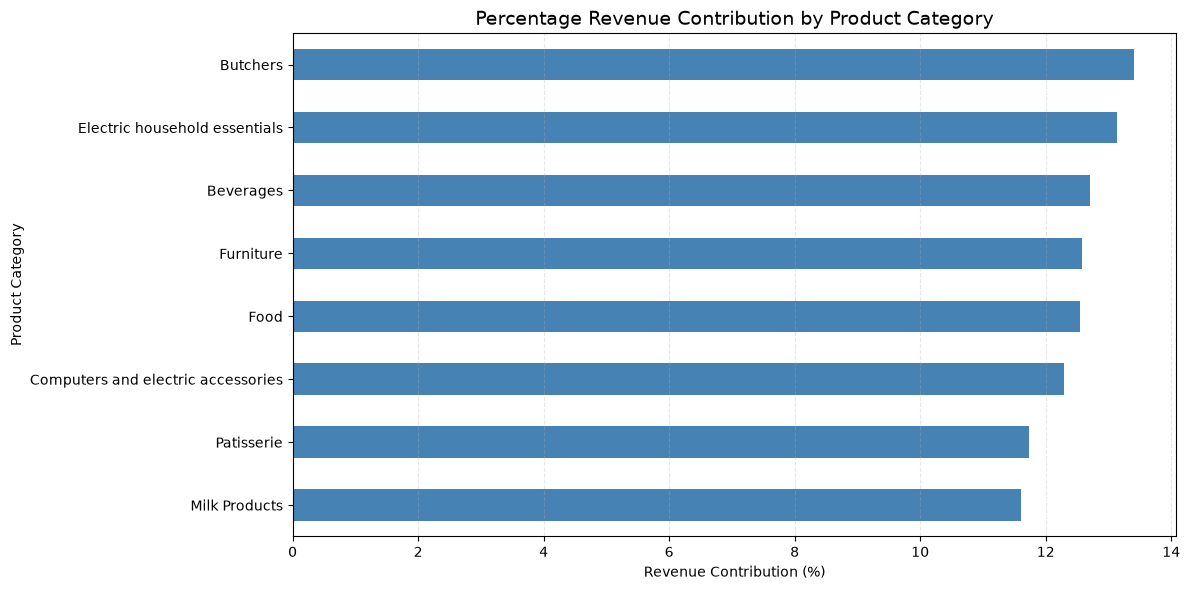

In [28]:

# Step 37: Visualize percentage revenue contribution

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

category_percentage.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title(
    "Percentage Revenue Contribution by Product Category",
    fontsize=14
)

plt.xlabel("Revenue Contribution (%)")
plt.ylabel("Product Category")

plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()



### Business Insight: Revenue Contribution by Product Category

The analysis shows that revenue is relatively evenly distributed across the eight product categories.

- Butchers generates the highest revenue contribution at 13.41%.
- Electric household essentials follows at 13.13%.
- Milk Products has the lowest contribution at 11.60%.
- The difference between the highest and lowest categories is only 1.81 percentage points.

**Business Interpretation:**

The relatively balanced revenue distribution suggests that the business is not heavily dependent on one product category.

**Recommendation:**

Management should investigate profitability, sales volume, and growth trends before deciding which categories deserve additional investment. Revenue contribution alone does not establish profitability.


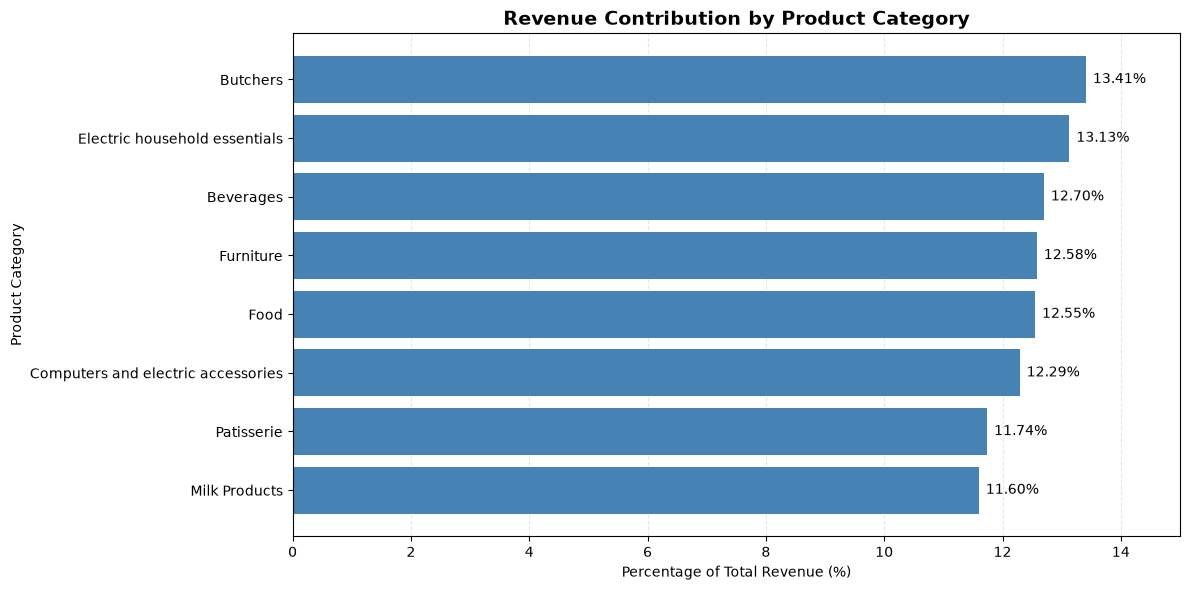

In [29]:

# Step 38: Improve the revenue contribution chart

import matplotlib.pyplot as plt

# Sort categories from lowest to highest
sorted_percentage = category_percentage.sort_values()

fig, ax = plt.subplots(figsize=(12, 6))

# Create horizontal bars
bars = ax.barh(
    sorted_percentage.index,
    sorted_percentage.values,
    color="steelblue"
)

# Add percentage labels
ax.bar_label(
    bars,
    labels=[f"{value:.2f}%" for value in sorted_percentage.values],
    padding=5
)

# Chart formatting
ax.set_title(
    "Revenue Contribution by Product Category",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Percentage of Total Revenue (%)")
ax.set_ylabel("Product Category")
ax.set_xlim(0, 15)

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

# Save the chart in high resolution
plt.savefig(
    "revenue_contribution_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [30]:
import os

filename = "revenue_contribution_by_category.png"

print("File exists:", os.path.exists(filename))
print("Working directory:", os.getcwd())

File exists: True
Working directory: C:\Users\hp\OneDrive\Desktop\Ecommerce_Sales_Analysis


In [31]:

# Step 40: Calculate total revenue by year

# Ensure transaction dates are in datetime format
df_revenue["Transaction Date"] = pd.to_datetime(
    df_revenue["Transaction Date"]
)

# Extract the year from each transaction date
df_revenue["Transaction Year"] = (
    df_revenue["Transaction Date"].dt.year
)

# Calculate total revenue for each year
yearly_revenue = (
    df_revenue.groupby("Transaction Year")["Total Spent"]
    .sum()
    .sort_index()
)

# Display the results
print("Total Revenue by Year:")
print(yearly_revenue.round(2))


Total Revenue by Year:
Transaction Year
2022    510329.5
2023    491312.0
2024    524881.0
2025     25548.5
Name: Total Spent, dtype: float64


In [32]:

# Step 41: Check transaction date coverage by year

year_coverage = (
    df_revenue.groupby("Transaction Year")
    .agg(
        First_Transaction=("Transaction Date", "min"),
        Last_Transaction=("Transaction Date", "max"),
        Total_Transactions=("Transaction Date", "count"),
        Months_Recorded=("Transaction Date",
                         lambda x: x.dt.to_period("M").nunique())
    )
)

print("Transaction Date Coverage by Year:")
print(year_coverage)


Transaction Date Coverage by Year:
                 First_Transaction Last_Transaction  Total_Transactions  \
Transaction Year                                                          
2022                    2022-01-01       2022-12-31                3925   
2023                    2023-01-01       2023-12-31                3808   
2024                    2024-01-01       2024-12-31                4036   
2025                    2025-01-01       2025-01-18                 202   

                  Months_Recorded  
Transaction Year                   
2022                           12  
2023                           12  
2024                           12  
2025                            1  


In [33]:

# Step 42: Compare January 1–18 revenue across years

# Select transactions occurring between January 1 and January 18
january_comparison = df_revenue[
    (df_revenue["Transaction Date"].dt.month == 1) &
    (df_revenue["Transaction Date"].dt.day <= 18)
]

# Calculate revenue for the same period in each year
january_revenue = (
    january_comparison
    .groupby("Transaction Year")["Total Spent"]
    .sum()
    .sort_index()
)

print("Revenue Comparison: January 1–18")
print(january_revenue.round(2))


Revenue Comparison: January 1–18
Transaction Year
2022    28906.5
2023    29420.5
2024    26497.0
2025    25548.5
Name: Total Spent, dtype: float64


In [34]:

# Step 42: Compare January 1–18 revenue across years

# Ensure transaction dates are in datetime format
import pandas as pd
df_revenue["Transaction Date"] = pd.to_datetime(
    df_revenue["Transaction Date"],
    errors="coerce"
)

# Select transactions occurring between January 1 and January 18
january_comparison = df_revenue[
    (df_revenue["Transaction Date"].dt.month == 1) &
    (df_revenue["Transaction Date"].dt.day <= 18)
].copy()

# Extract the transaction year
january_comparison["Transaction Year"] = (
    january_comparison["Transaction Date"].dt.year
)

# Calculate revenue for the same period in each year
january_revenue = (
    january_comparison
    .groupby("Transaction Year")["Total Spent"]
    .sum()
    .sort_index()
)

# Display the results
print("Revenue Comparison: January 1–18")
print(january_revenue.round(2))


Revenue Comparison: January 1–18
Transaction Year
2022    28906.5
2023    29420.5
2024    26497.0
2025    25548.5
Name: Total Spent, dtype: float64


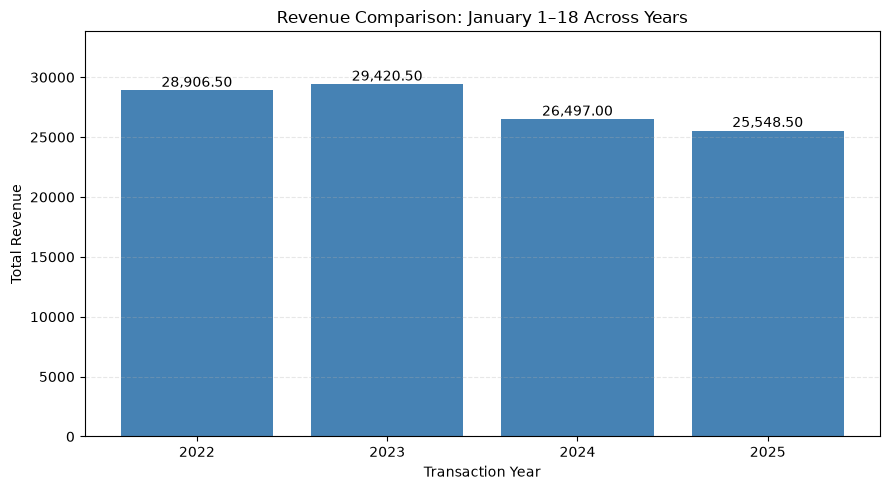

In [35]:
# Step 43: Visualize January 1–18 revenue across years

import matplotlib.pyplot as plt

# Create the bar chart
plt.figure(figsize=(9, 5))

plt.bar(
    january_revenue.index.astype(str),
    january_revenue.values,
    color="steelblue"
)

# Add chart labels
plt.title("Revenue Comparison: January 1–18 Across Years")
plt.xlabel("Transaction Year")
plt.ylabel("Total Revenue")

# Display revenue values above each bar
for i, value in enumerate(january_revenue.values):
    plt.text(i, value + 300, f"{value:,.2f}", ha="center")

plt.ylim(0, january_revenue.max() * 1.15)
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()

# Save the chart
plt.savefig(
    "images/january_revenue_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Key Findings: January 1–18 Revenue Comparison

- Revenue peaked in 2023 at 29,420.50.
- Revenue declined to 26,497.00 in 2024 and 25,548.50 in 2025.
- The January 1–18 revenue for 2025 was approximately 13.2% lower than the corresponding period in 2023.
- Comparing identical calendar periods avoids the misleading conclusions that could arise from comparing partial-year 2025 data against full-year totals.

**Business Insight:** The declining revenue trend after 2023 warrants further investigation into transaction volume, average transaction value, customer behavior, and product-category performance. The observed decline does not, by itself, establish its cause.

In [36]:

# Step 44: Calculate year-over-year revenue change

revenue_2024 = january_revenue.loc[2024]
revenue_2025 = january_revenue.loc[2025]

percentage_change = (
    (revenue_2025 - revenue_2024) / revenue_2024
) * 100

print(f"2024 Revenue: {revenue_2024:,.2f}")
print(f"2025 Revenue: {revenue_2025:,.2f}")
print(f"Revenue Percentage Change: {percentage_change:.2f}%")


2024 Revenue: 26,497.00
2025 Revenue: 25,548.50
Revenue Percentage Change: -3.58%


In [37]:

# Step 45: Compare transaction volume and average spending

january_performance = (
    january_comparison
    .groupby("Transaction Year")
    .agg(
        Total_Revenue=("Total Spent", "sum"),
        Transactions=("Transaction ID", "count"),
        Average_Transaction_Value=("Total Spent", "mean")
    )
    .round(2)
)

print("January 1–18 Sales Performance:")
print(january_performance)


January 1–18 Sales Performance:
                  Total_Revenue  Transactions  Average_Transaction_Value
Transaction Year                                                        
2022                    28906.5           210                     137.65
2023                    29420.5           218                     134.96
2024                    26497.0           207                     128.00
2025                    25548.5           202                     126.48


### Business Insight: Revenue Decline Analysis

Comparing January 1–18 across 2024 and 2025:

- Total revenue decreased by 3.58%.
- Transaction volume decreased by 2.42%.
- Average transaction value decreased by 1.19%.

**Key Finding:** The revenue decline was driven more by
reduced transaction volume than by lower average
spending per transaction.

**Business Recommendation:** Investigate the reasons
for fewer transactions, including customer activity,
conversion rates, and purchasing frequency.

**Limitation:** These results identify contributing
factors but do not establish causation.

In [38]:

# Step 46: Compare category revenue for January 1–18

category_comparison = (
    january_comparison[
        january_comparison["Transaction Year"].isin([2024, 2025])
    ]
    .pivot_table(
        index="Category",
        columns="Transaction Year",
        values="Total Spent",
        aggfunc="sum",
        fill_value=0
    )
)

# Calculate the revenue difference
category_comparison["Revenue Change"] = (
    category_comparison[2025] - category_comparison[2024]
)

# Sort from largest decline to largest increase
category_comparison = category_comparison.sort_values(
    "Revenue Change"
)

print("Category Revenue Comparison: 2024 vs 2025")
print(category_comparison.round(2))


Category Revenue Comparison: 2024 vs 2025
Transaction Year                      2024    2025  Revenue Change
Category                                                          
Electric household essentials       4122.5  2984.5         -1138.0
Furniture                           3493.0  2686.0          -807.0
Beverages                           4056.0  3554.5          -501.5
Patisserie                          2094.0  1732.5          -361.5
Butchers                            4189.0  3849.5          -339.5
Milk Products                       1968.5  2086.0           117.5
Food                                3779.5  4267.5           488.0
Computers and electric accessories  2794.5  4388.0          1593.5


In [39]:

# Step 47: Calculate percentage revenue change by category

category_comparison["Percentage Change"] = (
    (category_comparison[2025] - category_comparison[2024])
    / category_comparison[2024]
) * 100

print("Category Revenue Growth and Decline (%):")
print(category_comparison.round(2))


Category Revenue Growth and Decline (%):
Transaction Year                      2024    2025  Revenue Change  \
Category                                                             
Electric household essentials       4122.5  2984.5         -1138.0   
Furniture                           3493.0  2686.0          -807.0   
Beverages                           4056.0  3554.5          -501.5   
Patisserie                          2094.0  1732.5          -361.5   
Butchers                            4189.0  3849.5          -339.5   
Milk Products                       1968.5  2086.0           117.5   
Food                                3779.5  4267.5           488.0   
Computers and electric accessories  2794.5  4388.0          1593.5   

Transaction Year                    Percentage Change  
Category                                               
Electric household essentials                  -27.60  
Furniture                                      -23.10  
Beverages                         

In [40]:

# Step 48: Investigate category transaction performance

category_performance = (
    january_comparison[
        january_comparison["Transaction Year"].isin([2024, 2025])
    ]
    .groupby(["Category", "Transaction Year"])
    .agg(
        Transactions=("Transaction ID", "count"),
        Average_Transaction_Value=("Total Spent", "mean")
    )
    .round(2)
)

print("Category Transaction Performance: 2024 vs 2025")
print(category_performance)


Category Transaction Performance: 2024 vs 2025
                                                     Transactions  \
Category                           Transaction Year                 
Beverages                          2024                        27   
                                   2025                        25   
Butchers                           2024                        29   
                                   2025                        25   
Computers and electric accessories 2024                        21   
                                   2025                        30   
Electric household essentials      2024                        32   
                                   2025                        25   
Food                               2024                        31   
                                   2025                        36   
Furniture                          2024                        28   
                                   2025                 

In [41]:

# Step 49: Investigate furniture transaction volume

# Extract furniture transactions for January 1–18
furniture_data = january_comparison[
    (january_comparison["Category"] == "Furniture") &
    (january_comparison["Transaction Year"].isin([2024, 2025]))
]

# Compare transaction counts and average spending
furniture_performance = (
    furniture_data
    .groupby("Transaction Year")
    .agg(
        Transactions=("Transaction ID", "count"),
        Total_Revenue=("Total Spent", "sum"),
        Average_Transaction_Value=("Total Spent", "mean")
    )
    .round(2)
)

print("Furniture Sales Performance: January 1–18")
print(furniture_performance)



Furniture Sales Performance: January 1–18
                  Transactions  Total_Revenue  Average_Transaction_Value
Transaction Year                                                        
2024                        28         3493.0                     124.75
2025                        20         2686.0                     134.30


In [42]:

# Step 51: Analyze payment method performance

# Group revenue-ready transactions by payment method
payment_performance = (
    df_revenue
    .groupby("Payment Method")
    .agg(
        Total_Revenue=("Total Spent", "sum"),
        Transactions=("Total Spent", "count"),
        Average_Transaction_Value=("Total Spent", "mean")
    )
    .sort_values("Total_Revenue", ascending=False)
    .round(2)
)

# Display results
print("Sales Performance by Payment Method:")
print(payment_performance)

# Verify total revenue
print("\nTotal Revenue Across Payment Methods:")
print(payment_performance["Total_Revenue"].sum().round(2))


Sales Performance by Payment Method:
                Total_Revenue  Transactions  Average_Transaction_Value
Payment Method                                                        
Cash                 537710.0          4103                     131.05
Digital Wallet       507279.0          3941                     128.72
Credit Card          507082.0          3927                     129.13

Total Revenue Across Payment Methods:
1552071.0


## Key analytical insight:
Cash leads in all three performance metrics. However, we should not automatically conclude that cash payments cause customers to spend more. Our analysis shows an association, not causation.

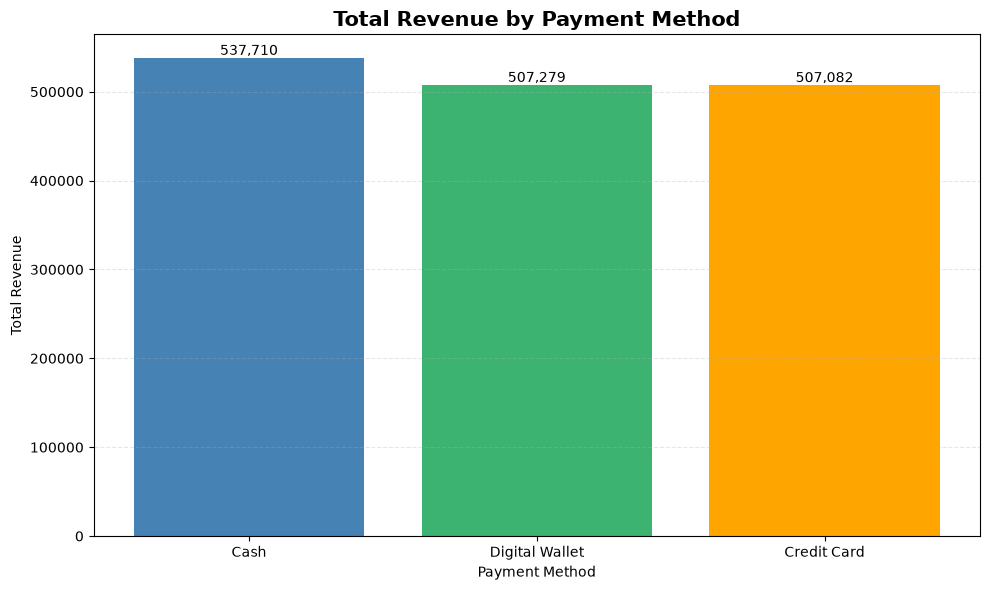

In [43]:

# Step 53: Visualize revenue by payment method

import matplotlib.pyplot as plt

# Extract revenue by payment method
payment_revenue = payment_performance["Total_Revenue"]

# Create bar chart
plt.figure(figsize=(10, 6))

bars = plt.bar(
    payment_revenue.index,
    payment_revenue.values,
    color=["steelblue", "mediumseagreen", "orange"]
)

# Add chart title and labels
plt.title(
    "Total Revenue by Payment Method",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Payment Method")
plt.ylabel("Total Revenue")

# Add revenue labels above bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:,.0f}",
        ha="center",
        va="bottom"
    )

# Improve layout
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

# Save chart for portfolio
plt.savefig(
    "revenue_by_payment_method.png",
    dpi=300,
    bbox_inches="tight"
)

# Display chart
plt.show()


In [44]:

# Step 54: Calculate revenue contribution by payment method

# Calculate total revenue across all payment methods
total_revenue = payment_performance["Total_Revenue"].sum()

# Calculate percentage contribution for each payment method
payment_performance["Revenue_Percentage"] = (
    payment_performance["Total_Revenue"] / total_revenue
) * 100

# Display payment method contributions
print("Revenue Contribution by Payment Method:")
print(
    payment_performance[
        ["Total_Revenue", "Revenue_Percentage"]
    ].round(2)
)

# Verify that all percentages add up to 100%
print(
    "\nTotal Revenue Contribution:",
    round(payment_performance["Revenue_Percentage"].sum(), 2),
    "%"
)


Revenue Contribution by Payment Method:
                Total_Revenue  Revenue_Percentage
Payment Method                                   
Cash                 537710.0               34.64
Digital Wallet       507279.0               32.68
Credit Card          507082.0               32.67

Total Revenue Contribution: 100.0 %


In [45]:
# Step 55: Calculate transaction share by payment method

payment_performance["Transaction_Percentage"] = (
    payment_performance["Transactions"]
    / payment_performance["Transactions"].sum()
    * 100
)

print(
    payment_performance[
        ["Transactions", "Transaction_Percentage"]
    ].round(2)
)

                Transactions  Transaction_Percentage
Payment Method                                      
Cash                    4103                   34.27
Digital Wallet          3941                   32.92
Credit Card             3927                   32.80


In [46]:
# Step 56: Compare revenue and transaction shares

payment_performance["Share_Difference"] = (
    payment_performance["Revenue_Percentage"]
    - payment_performance["Transaction_Percentage"]
)

print("Payment Method Share Comparison:")
print(
    payment_performance[
        [
            "Revenue_Percentage",
            "Transaction_Percentage",
            "Share_Difference"
        ]
    ].round(2)
)


Payment Method Share Comparison:
                Revenue_Percentage  Transaction_Percentage  Share_Difference
Payment Method                                                              
Cash                         34.64                   34.27              0.37
Digital Wallet               32.68                   32.92             -0.24
Credit Card                  32.67                   32.80             -0.13


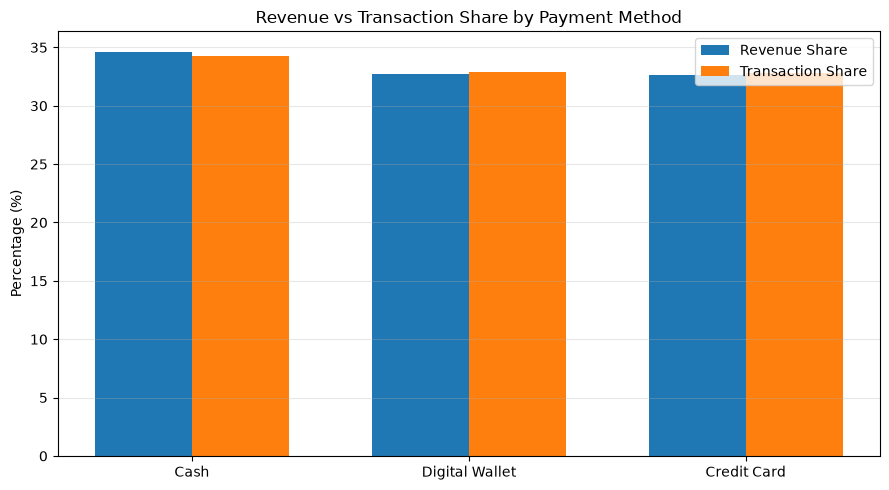

In [47]:
# Step 57: Compare payment method shares visually

import matplotlib.pyplot as plt
import numpy as np

methods = payment_performance.index
x = np.arange(len(methods))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    payment_performance["Revenue_Percentage"],
    width,
    label="Revenue Share"
)

plt.bar(
    x + width/2,
    payment_performance["Transaction_Percentage"],
    width,
    label="Transaction Share"
)

plt.xticks(x, methods)
plt.ylabel("Percentage (%)")
plt.title("Revenue vs Transaction Share by Payment Method")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

### Payment Method Analysis — Key Findings

- Cash accounts for the largest share of revenue (34.64%) and transactions (34.27%).
- Digital Wallet and Credit Card contribute approximately one-third of total revenue each.
- Revenue share closely matches transaction share across all three payment methods.
- These findings suggest relatively balanced payment method usage, with no major differences in average transaction value.

**Business recommendation:** Continue supporting all three payment methods rather than prioritizing one based solely on revenue contribution.

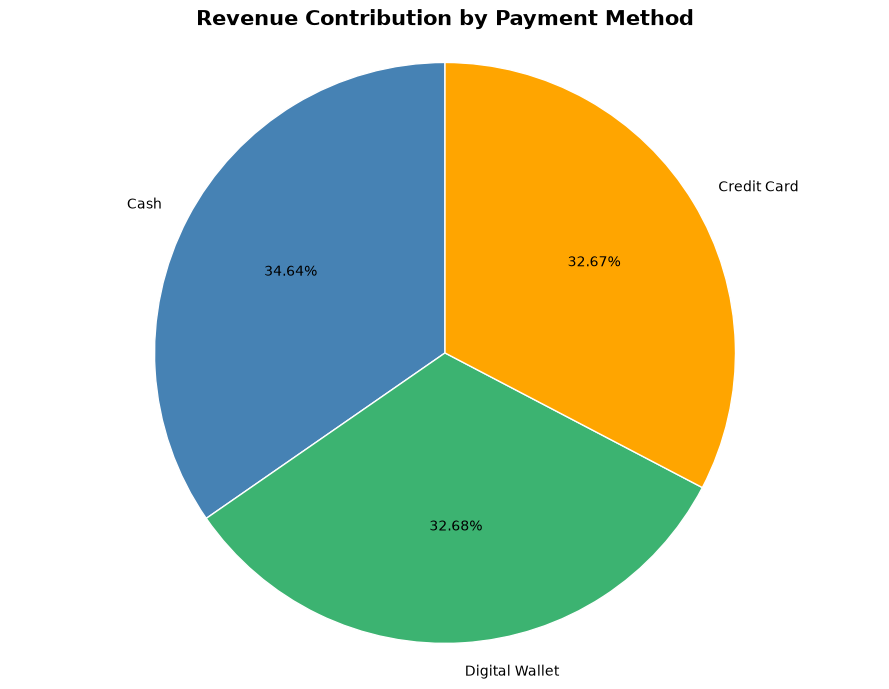

<Figure size 640x480 with 0 Axes>

In [48]:

# Step 58: Visualize payment method revenue contribution

import matplotlib.pyplot as plt

# Use unrounded revenue values for accurate percentages
payment_revenue = payment_performance["Total_Revenue"]

# Create pie chart
plt.figure(figsize=(9, 7))

plt.pie(
    payment_revenue,
    labels=payment_revenue.index,
    autopct="%1.2f%%",
    startangle=90,
    colors=["steelblue", "mediumseagreen", "orange"],
    wedgeprops={"edgecolor": "white"}
)

# Add chart title
plt.title(
    "Revenue Contribution by Payment Method",
    fontsize=15,
    fontweight="bold"
)

plt.axis("equal")
plt.tight_layout()

# Save chart for portfolio
plt.savefig("payment_method_revenue_share.png", dpi=300, bbox_inches="tight")

# Display chart
plt.show()


# Display chart
plt.savefig("payment_method_revenue_share.png", dpi=300, bbox_inches="tight")
plt.show()


In [49]:

# Step 59: Inspect columns for customer analysis

print("Available Columns:")
print(df_revenue.columns.tolist())


Available Columns:
['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit', 'Quantity', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date', 'Discount Applied', 'Transaction Year']


In [50]:

# Step 60: Analyze customer purchase frequency

# Count transactions for each customer
customer_transactions = (
    df_revenue.groupby("Customer ID")["Transaction ID"]
    .nunique()
    .sort_values(ascending=False)
)

# Calculate customer metrics
total_customers = len(customer_transactions)

one_time_customers = (customer_transactions == 1).sum()

repeat_customers = (customer_transactions > 1).sum()

# Display results
print("Customer Purchase Frequency Analysis")
print("Total Unique Customers:", total_customers)
print("One-Time Customers:", one_time_customers)
print("Repeat Customers:", repeat_customers)

print("\nTop 10 Customers by Transaction Count:")
print(customer_transactions.head(10))


Customer Purchase Frequency Analysis
Total Unique Customers: 25
One-Time Customers: 0
Repeat Customers: 25

Top 10 Customers by Transaction Count:
Customer ID
CUST_24    519
CUST_05    516
CUST_13    508
CUST_08    507
CUST_15    501
CUST_09    498
CUST_16    494
CUST_01    485
CUST_11    481
CUST_23    481
Name: Transaction ID, dtype: int64


## Important analytical insight
All 25 customer IDs appear in multiple transactions. However, we should not immediately conclude that the business has a 100% real-world customer retention rate.

Why? Because the dataset contains only 25 customer IDs, each associated with hundreds of transactions. This could reflect a synthetic dataset or a limited set of customer identifiers.

A repeat purchase count is also different from a formal customer retention metric.

In [51]:

# Step 61: Analyze customer spending and revenue contribution

# Calculate revenue and transaction count for each customer
customer_spending = (
    df_revenue.groupby("Customer ID")
    .agg(
        Total_Revenue=("Total Spent", "sum"),
        Transactions=("Transaction ID", "nunique")
    )
)

# Calculate average transaction value
customer_spending["Average_Transaction_Value"] = (
    customer_spending["Total_Revenue"] /
    customer_spending["Transactions"]
)

# Calculate each customer's contribution to total revenue
customer_spending["Revenue_Contribution_Percent"] = (
    customer_spending["Total_Revenue"] /
    customer_spending["Total_Revenue"].sum()
) * 100

# Sort customers by highest revenue
customer_spending = customer_spending.sort_values(
    by="Total_Revenue",
    ascending=False
)

# Display the top 10 customers
print("Top 10 Customers by Total Revenue:")
print(customer_spending.head(10).round(2))

# Verify revenue
print("\nTotal Customer Revenue:")
print(round(customer_spending["Total_Revenue"].sum(), 2))


Top 10 Customers by Total Revenue:
             Total_Revenue  Transactions  Average_Transaction_Value  \
Customer ID                                                           
CUST_24            68452.0           519                     131.89   
CUST_08            67351.5           507                     132.84   
CUST_05            66974.5           516                     129.80   
CUST_16            65570.5           494                     132.73   
CUST_13            65037.0           508                     128.03   
CUST_23            64507.0           481                     134.11   
CUST_10            63155.5           481                     131.30   
CUST_15            63117.5           501                     125.98   
CUST_21            62933.0           476                     132.21   
CUST_02            62046.5           467                     132.86   

             Revenue_Contribution_Percent  
Customer ID                                
CUST_24                 

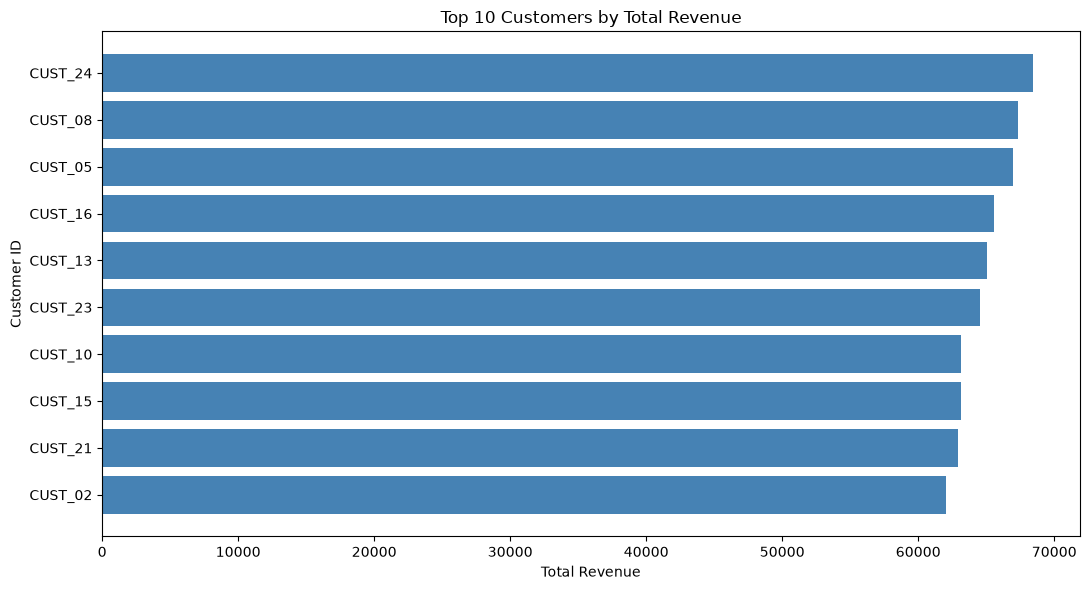

In [52]:
# Step 62: Visualize top 10 customers by revenue

import matplotlib.pyplot as plt

top_customers = customer_spending.head(10)

plt.figure(figsize=(11, 6))

plt.barh(
    top_customers.index,
    top_customers["Total_Revenue"],
    color="steelblue"
)

plt.title("Top 10 Customers by Total Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Customer ID")

plt.gca().invert_yaxis()
plt.tight_layout()

# Save chart for GitHub portfolio
plt.savefig(
    "top_10_customers_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Customer Analysis — Key Findings

- The dataset contains 25 unique customer IDs, all associated with multiple transactions.
- CUST_24 generated the highest total revenue of 68,452, representing 4.41% of overall sales.
- The top 10 customers have relatively similar spending levels.
- No single customer dominates total revenue, suggesting revenue is distributed across multiple customer IDs.
- The high frequency of repeat transactions should not be interpreted as a 100% customer retention rate without further investigation.

**Business recommendation:** Monitor customer spending patterns, identify valuable customer segments, and investigate repeat purchasing behavior to support targeted marketing and customer retention strategies.

In [53]:

# Step 63: Calculate customer revenue concentration

# Calculate total customer revenue
total_customer_revenue = customer_spending["Total_Revenue"].sum()

# Calculate revenue generated by top 5 customers
top_5_revenue = customer_spending.head(5)["Total_Revenue"].sum()

# Calculate revenue generated by top 10 customers
top_10_revenue = customer_spending.head(10)["Total_Revenue"].sum()

# Convert revenue into percentages
top_5_percentage = (top_5_revenue / total_customer_revenue) * 100
top_10_percentage = (top_10_revenue / total_customer_revenue) * 100

# Display results
print(f"Top 5 Customer Revenue Contribution: {top_5_percentage:.2f}%")
print(f"Top 10 Customer Revenue Contribution: {top_10_percentage:.2f}%")


Top 5 Customer Revenue Contribution: 21.48%
Top 10 Customer Revenue Contribution: 41.82%


In [54]:

# Step 64: Calculate average customer spending

# Calculate average revenue per customer
average_customer_revenue = (
    customer_spending["Total_Revenue"].mean()
)

# Find highest and lowest customer revenue
highest_customer_revenue = (
    customer_spending["Total_Revenue"].max()
)

lowest_customer_revenue = (
    customer_spending["Total_Revenue"].min()
)

# Display results
print(f"Average Revenue Per Customer: {average_customer_revenue:,.2f}")
print(f"Highest Customer Revenue: {highest_customer_revenue:,.2f}")
print(f"Lowest Customer Revenue: {lowest_customer_revenue:,.2f}")


Average Revenue Per Customer: 62,082.84
Highest Customer Revenue: 68,452.00
Lowest Customer Revenue: 57,155.50



### Customer Revenue Analysis — Key Findings

- The top 5 customers contribute 21.48% of total revenue.
- The top 10 customers contribute 41.82% of total revenue.
- Average revenue per customer is 62,082.84.
- The highest customer revenue is 68,452.00, while the lowest is 57,155.50.
- Revenue is relatively evenly distributed across the 25 customer IDs.

**Important limitation:** The dataset contains only 25 customer IDs, each associated with multiple transactions. These results describe the dataset and should not automatically be generalized to real-world customer behavior.


In [55]:

# Step 65: Analyze customer spending variability

# Calculate standard deviation
spending_std = customer_spending["Total_Revenue"].std()

# Calculate coefficient of variation
spending_cv = (
    spending_std / average_customer_revenue
) * 100

# Display results
print(f"Average Customer Revenue: {average_customer_revenue:,.2f}")
print(f"Standard Deviation: {spending_std:,.2f}")
print(f"Coefficient of Variation: {spending_cv:.2f}%")


Average Customer Revenue: 62,082.84
Standard Deviation: 2,933.82
Coefficient of Variation: 4.73%


In [56]:

# Step 66: Customer Segmentation by Revenue

# Create a copy to preserve the original analysis
customer_segments = customer_spending.copy()

# Divide customers into three revenue-based groups
customer_segments["Customer_Segment"] = pd.qcut(
    customer_segments["Total_Revenue"].rank(method="first"),
    q=3,
    labels=["Low Revenue", "Medium Revenue", "High Revenue"]
)

# Summarize customer segments
segment_summary = (
    customer_segments.groupby(
        "Customer_Segment", observed=True
    )
    .agg(
        Customers=("Total_Revenue", "count"),
        Total_Revenue=("Total_Revenue", "sum"),
        Average_Revenue=("Total_Revenue", "mean")
    )
)

# Calculate each segment's contribution to total revenue
segment_summary["Revenue_Percentage"] = (
    segment_summary["Total_Revenue"]
    / segment_summary["Total_Revenue"].sum()
    * 100
)

# Display results
print("Customer Revenue Segmentation:")
print(segment_summary.round(2))


Customer Revenue Segmentation:
                  Customers  Total_Revenue  Average_Revenue  \
Customer_Segment                                              
Low Revenue               9       534298.5         59366.50   
Medium Revenue            8       493607.0         61700.88   
High Revenue              8       524165.5         65520.69   

                  Revenue_Percentage  
Customer_Segment                      
Low Revenue                    34.42  
Medium Revenue                 31.80  
High Revenue                   33.77  



### Customer Spending Variability and Segmentation

**Key Findings**

- Average customer revenue is 62,082.84.
- Standard deviation is 2,933.82.
- The coefficient of variation is 4.73%, indicating relatively low variation in customer revenue.
- Low-revenue customers contribute 34.42% of total revenue.
- Medium-revenue customers contribute 31.80%.
- High-revenue customers contribute 33.77%.

**Business Interpretation**

Customer revenue is relatively evenly distributed across the three revenue-based segments. No single segment overwhelmingly dominates total revenue.

**Limitation**

The dataset contains only 25 customer IDs. The segments are based on relative revenue rankings and should not be interpreted as evidence of real-world customer loyalty or lifetime value.


In [57]:

# Step 67: Analyze customer purchasing behavior over time

# Create a copy of the transaction data
customer_activity = df_revenue.copy()

# Ensure transaction dates are datetime
customer_activity["Transaction Date"] = pd.to_datetime(
    customer_activity["Transaction Date"]
)

# Create a monthly period column
customer_activity["Transaction Month"] = (
    customer_activity["Transaction Date"].dt.to_period("M")
)

# Calculate monthly customer activity
monthly_customer_activity = (
    customer_activity.groupby("Transaction Month")
    .agg(
        Active_Customers=("Customer ID", "nunique"),
        Transactions=("Transaction ID", "count"),
        Total_Revenue=("Total Spent", "sum")
    )
    .sort_index()
)

# Calculate transactions per active customer
monthly_customer_activity["Transactions_Per_Customer"] = (
    monthly_customer_activity["Transactions"]
    / monthly_customer_activity["Active_Customers"]
)

# Display results
print("Monthly Customer Purchasing Behavior:")
print(monthly_customer_activity.round(2).to_string())


Monthly Customer Purchasing Behavior:
                   Active_Customers  Transactions  Total_Revenue  Transactions_Per_Customer
Transaction Month                                                                          
2022-01                          25           368        52911.5                      14.72
2022-02                          25           313        43325.5                      12.52
2022-03                          25           339        40996.0                      13.56
2022-04                          25           334        40442.0                      13.36
2022-05                          25           315        40347.5                      12.60
2022-06                          25           321        42576.0                      12.84
2022-07                          25           349        44471.5                      13.96
2022-08                          25           331        41333.5                      13.24
2022-09                          25       

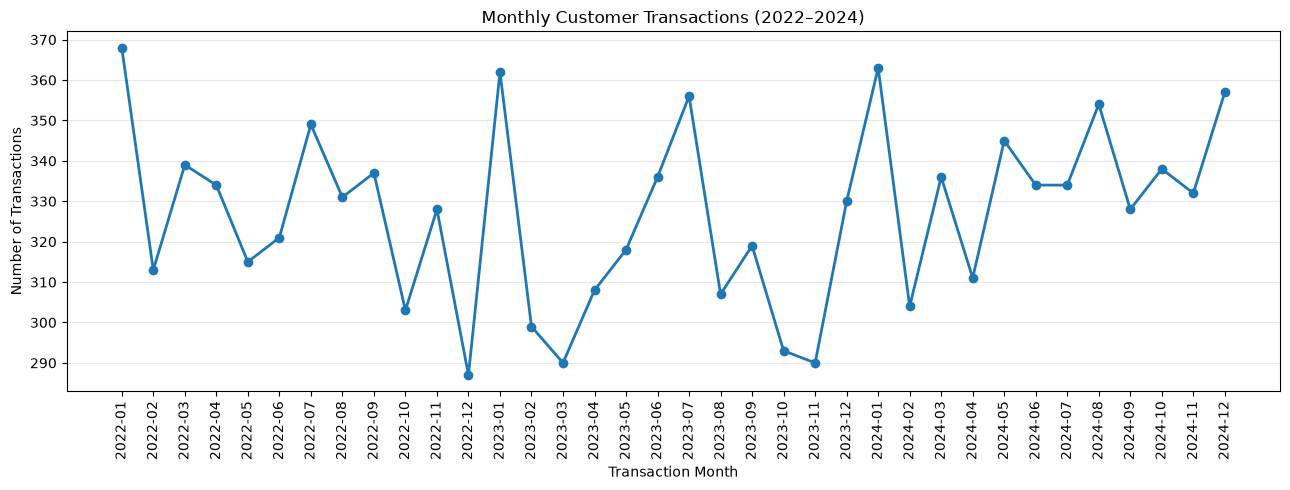

In [58]:

# Step 68: Visualize monthly customer purchasing behavior

import matplotlib.pyplot as plt

# Exclude incomplete January 2025
monthly_activity_full = monthly_customer_activity.loc[
    monthly_customer_activity.index < pd.Period("2025-01")
]

# Create the chart
plt.figure(figsize=(13, 5))

plt.plot(
    monthly_activity_full.index.astype(str),
    monthly_activity_full["Transactions"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Customer Transactions (2022–2024)")
plt.xlabel("Transaction Month")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=90)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Save chart for GitHub portfolio
plt.savefig(
    "monthly_customer_transactions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## Customer Analysis: Findings and Business Recommendations

### Key Findings

The customer analysis examined purchasing frequency, revenue contribution, customer segmentation, and monthly transaction activity.

**1. Customer purchasing frequency**

The dataset contains 25 unique customer IDs, all associated with multiple transactions. All 25 IDs also appear in every recorded month. This suggests a fixed customer population in the dataset rather than necessarily demonstrating genuine customer retention.

**2. Customer revenue distribution**

- Average revenue per customer ID: 62,082.84
- Standard deviation: 2,933.82
- Coefficient of variation: 4.73%
- Top 5 customer revenue contribution: 21.48%
- Top 10 customer revenue contribution: 41.82%

The relatively low coefficient of variation indicates that aggregate customer revenue is distributed fairly evenly across the recorded customer IDs.

**3. Customer segmentation**

Customers were divided into low-, medium-, and high-revenue segments based on their relative spending rankings.

The low-revenue segment contributed 34.42% of total revenue, the medium-revenue segment contributed 31.80%, and the high-revenue segment contributed 33.77%.

The low-revenue segment contributed slightly more total revenue because it contained nine customers, compared with eight customers in each of the other segments.

**4. Monthly purchasing behavior**

Monthly transaction volumes fluctuated between 2022 and 2024, without a clear sustained upward or downward trend. January showed relatively high transaction activity across all three years.

### Business Recommendations

1. **Investigate customer identification:** Verify whether the 25 customer IDs represent individual customers or reused identifiers before calculating retention or loyalty metrics.

2. **Monitor transaction activity:** Track monthly transaction counts and revenue to identify unusual fluctuations and investigate potential seasonal patterns.

3. **Develop targeted customer strategies:** Use revenue segmentation as an initial exploratory tool, but validate customer identities and purchasing histories before implementing personalized campaigns.

4. **Monitor revenue concentration:** Track how much revenue comes from the highest-spending customer IDs to identify potential dependence on a small customer group.

### Limitations

The dataset contains only 25 unique customer IDs, each associated with unusually frequent purchases. This limits the reliability of conclusions about real-world customer loyalty, retention, and segmentation.

Additionally, January 2025 contains only 18 days of transactions and was excluded from the full-month visualization.

### Conclusion

Customer revenue is relatively evenly distributed across the recorded customer IDs, while monthly transaction activity fluctuates without a clear long-term trend. Further validation of customer identifiers would improve the reliability of customer-level business recommendations.

# Final Business Insights and Recommendations

## Executive Summary


This E-commerce Sales Analysis project examines transaction data from 2022 through January 18, 2025, using Python, pandas, and Matplotlib to evaluate revenue performance, product categories, payment methods, and customer purchasing behavior.

### Key Findings

**1. Overall Revenue Performance**

The dataset generated total recorded revenue of **1,552,071** across the analyzed transactions.

**2. Payment Method Performance**

Cash contributed the highest share of revenue at **34.64%**, followed by Digital Wallets (**32.68%**) and Credit Cards (**32.67%**). Revenue was relatively evenly distributed across the three payment methods.

**3. Product Category Performance**

Between January 1–18, 2024 and the corresponding period in 2025, Computers and Electric Accessories recorded the strongest revenue growth (**57.02%**), while Electric Household Essentials experienced the largest decline (**27.60%**).

**4. Customer Revenue Distribution**

The top five recorded customer IDs contributed **21.48%** of total revenue, while the top ten contributed **41.82%**. Customer revenue showed relatively low variability, with a coefficient of variation of **4.73%**.

**5. Customer Behavior and Data Limitations**

The dataset contains only **25 unique customer IDs**, each associated with unusually frequent transactions. Therefore, conclusions about customer loyalty and retention require additional validation.

January 2025 also contains only 18 days of transactions, making full-month comparisons inappropriate without adjusting for the incomplete period.

### Overall Business Insight

The analysis highlights opportunities to monitor declining product categories, strengthen growing categories, maintain support for multiple payment methods, and improve customer data quality before implementing personalized retention strategies.



## Final Business Recommendations

Based on the findings from the E-commerce Sales Analysis, the following recommendations are proposed:

### 1. Strengthen High-Growth Product Categories
Investigate the factors behind the 57.02% revenue increase in Computers and Electric Accessories during January 1–18, 2025, compared with the same period in 2024. Evaluate inventory availability, pricing, and promotional activity before expanding investment.

### 2. Investigate Declining Product Categories
Electric Household Essentials experienced a 27.60% revenue decline over the comparable January periods. Review product demand, pricing, stock availability, and competitor activity to identify potential causes.

### 3. Maintain Multiple Payment Options
Cash, Digital Wallets, and Credit Cards each contributed approximately one-third of total revenue. Continue supporting all three payment methods and monitor transaction costs, customer preferences, and payment reliability.

### 4. Improve Customer Data Quality
Verify whether the 25 customer IDs represent genuine individual customers. Reliable identifiers are necessary before implementing loyalty programs, calculating retention rates, or developing personalized marketing campaigns.

### 5. Monitor Revenue Concentration
The top ten recorded customer IDs contributed 41.82% of total revenue. Monitor this concentration over time and investigate whether revenue depends disproportionately on a limited number of customers.

### 6. Improve Sales Performance Monitoring
Develop a recurring dashboard tracking revenue, transaction volume, average transaction value, product category performance, and payment method contributions. Compare equivalent reporting periods to avoid misleading conclusions from incomplete months.

## Final Project Conclusion

This project demonstrates how Python-based exploratory data analysis can transform transaction records into actionable business insights.

The findings identify opportunities to investigate product category performance, maintain accessible payment options, monitor revenue concentration, and improve customer data quality.

However, the recommendations are exploratory rather than causal conclusions. Further investigation and additional validated customer data would strengthen business decision-making.


In [59]:

import os

print("Current working directory:")
print(os.getcwd())

print("\nSaved chart images:")
for file in os.listdir():
    if file.lower().endswith(".png"):
        print(file)


Current working directory:
C:\Users\hp\OneDrive\Desktop\Ecommerce_Sales_Analysis

Saved chart images:
monthly_customer_transactions.png
payment_method_revenue_share.png
revenue_by_payment_method.png
revenue_contribution_by_category.png
top_10_customers_by_revenue.png
top_10_customers_revenue.png
